In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from sklearn import datasets

In [3]:
iris = datasets.load_iris()
X = iris.data
target = iris.target
Y = to_categorical(target).astype("uint8")
# 0 => [1 0 0]
# 1 => [0 1 0]
# 2 => [0 0 1]

In [4]:
idx = 0
print(X[idx])
print(target[idx])
print(Y[idx])

[5.1 3.5 1.4 0.2]
0
[1 0 0]


In [5]:
model = keras.Sequential(
  [
    layers.Dense(8, activation="relu", name="layer1", input_shape=(4,)),
    layers.Dense(3, activation="softmax", name="layer2"),
  ]
)

model.summary()

c:\Users\Hecto\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
y = model(X)
print(y[149])

tf.Tensor([0.979404   0.00862384 0.01197214], shape=(3,), dtype=float32)


In [7]:
optimizer = tf.keras.optimizers.SGD(learning_rate=0.03)
loss = tf.keras.losses.CategoricalCrossentropy()

model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])
history = model.fit(X, Y, epochs=500)

Epoch 1/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3333 - loss: 1.9804  
Epoch 2/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3067 - loss: 1.1642 
Epoch 3/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6667 - loss: 1.0810 
Epoch 4/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7400 - loss: 1.0297 
Epoch 5/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8000 - loss: 1.0005 
Epoch 6/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6667 - loss: 0.9820 
Epoch 7/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7067 - loss: 0.9580 
Epoch 8/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7733 - loss: 0.9355 
Epoch 9/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7267 - loss: 0.9144 
Epoch 10/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7133 - loss: 0.8938 
Epoch 11/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8133 - loss: 0.8719 
Epoch 12/500
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7267 - lo

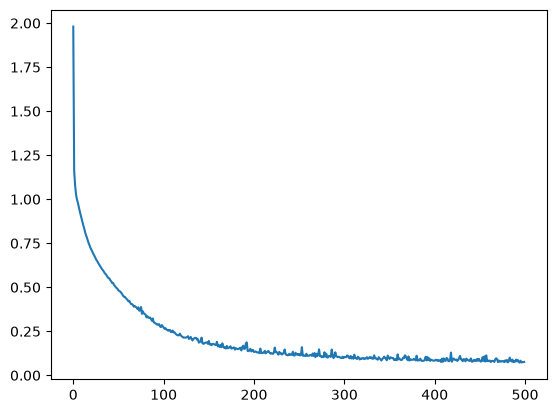

In [8]:
plt.plot(history.history['loss'])
plt.show()

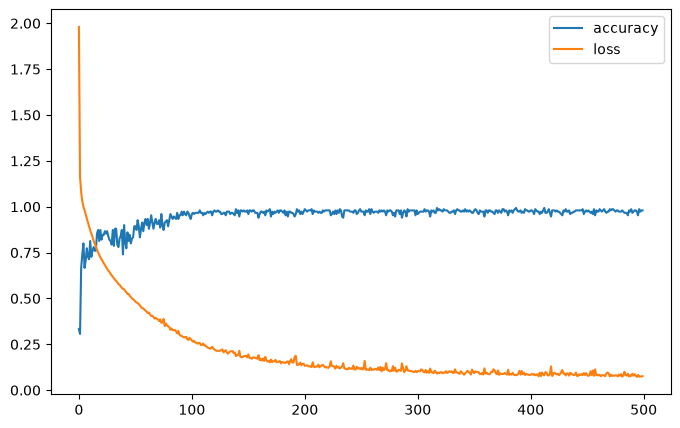

In [9]:
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.show()

In [10]:
model.predict(np.array([[3,3,1,1]]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


array([[9.9542135e-01, 4.3224595e-03, 2.5618874e-04]], dtype=float32)

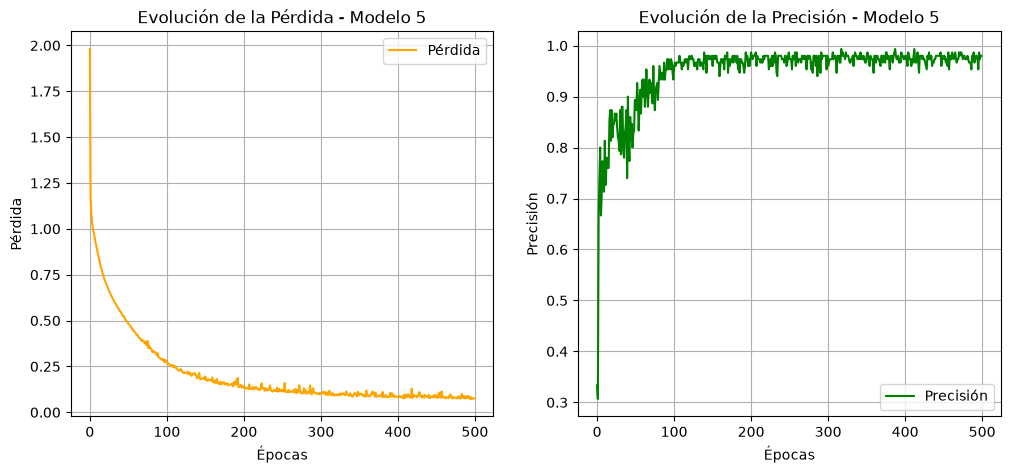

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
--- RESULTADOS ARCHIVO 5 ---
Clases Reales (Muestra):     [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Clases Predichas (Muestra):  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Exactitud final del modelo (Archivo 5): 98.00%


In [11]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. GRÁFICAS DE APRENDIZAJE (ARCHIVO 5) ---
plt.figure(figsize=(12, 5))

# Pérdida
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida', color='orange')
plt.title('Evolución de la Pérdida - Modelo 5')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.grid(True)
plt.legend()

# Precisión
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Precisión', color='green')
plt.title('Evolución de la Precisión - Modelo 5')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.grid(True)
plt.legend()

plt.show()

# --- 2. PREDICCIONES Y EXACTITUD (ARCHIVO 5) ---
predicciones_probabilidades = model.predict(X)
clases_predichas = np.argmax(predicciones_probabilidades, axis=1)
clases_reales = np.argmax(Y, axis=1)

print("--- RESULTADOS ARCHIVO 5 ---")
print("Clases Reales (Muestra):    ", clases_reales[:15])
print("Clases Predichas (Muestra): ", clases_predichas[:15])

exactitud_total = np.mean(clases_predichas == clases_reales) * 100
print(f"\nExactitud final del modelo (Archivo 5): {exactitud_total:.2f}%")